# Probabilistic Fractions Skill Score (pFSS)

The [Fractions Skill Score](./Fractions_Skill_Score.ipynb) (FSS) is a neighbourhood verification method for deterministic forecasts of binary events, such as rainfall above a threshold. Rather than comparing forecasts and observations grid point by grid point, it compares the *fraction* of grid points within a sliding window where the event is forecast and observed. This reduces the "double penalty" for forecasts that are close, but slightly displaced.

The probabilistic FSS (pFSS) extends the FSS to ensemble forecasts. [Necker et al. (2024)](https://doi.org/10.1002/qj.4824) compared several ways of calculating an ensemble FSS and recommend the pFSS. Instead of the forecast fraction from a single field, the pFSS uses the *neighbourhood ensemble probability* (NEP), which is the proportion of all grid points and ensemble members in a window that forecast the event:

$$\mathrm{NEP}_i = \frac{1}{JN}\sum_{j=1}^{J}\sum_{n=1}^{N}\mathrm{BP}_{ijn}$$

The pFSS is then

$$\mathrm{pFSS} = 1 - \frac{\sum_i \left(\mathrm{NEP}_i - \mathrm{NP}_{i,o}\right)^2}{\sum_i \mathrm{NEP}_i^2 + \sum_i \mathrm{NP}_{i,o}^2}$$

where

- $\mathrm{BP}_{ijn}$ (the binary probability) is 1 if ensemble member $n$ forecasts the event at grid point $j$ in window $i$, and 0 otherwise,
- $J$ is the number of grid points in a window and $N$ is the number of ensemble members,
- $\mathrm{NP}_{i,o}$ is the fraction of grid points in window $i$ where the event was observed, and
- the sums are over all window positions $i$.

The pFSS ranges from 0 to 1, where 1 is a perfect score. With a single ensemble member ($N=1$), the pFSS is the same as the FSS.

**Note:** by default, `scores` defines an event as a value strictly greater than the threshold (`threshold_operator=np.greater`) to be consistent with the standard FSS implementation in scores, whereas Necker et al. (2024) use greater than or equal to.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

from scores.probability import pfss_for_ensemble

# Uncomment the following line to learn more about the pFSS
# help(pfss_for_ensemble)

## A synthetic example

We will create a synthetic rainfall field containing four thunderstorms to use as our observations. We then create a 50-member ensemble forecast, where every member has the same four storms, but each storm is randomly displaced. This mimics an ensemble that correctly predicts the thunderstorms, but is uncertain about exactly where they will be.

We will treat an event as "rainfall greater than 2 mm".

In [2]:
rng = np.random.default_rng(100)
y, x = np.mgrid[0:100, 0:100]  # a 100 x 100 grid


def rain_field(centres, width=4):
    """A rainfall field (mm) made up of Gaussian-shaped storms at the given (x, y) centres."""
    return sum(10 * np.exp(-((x - cx) ** 2 + (y - cy) ** 2) / (2 * width**2)) for cx, cy in centres)


storm_centres = rng.uniform(15, 85, size=(4, 2))
obs = xr.DataArray(rain_field(storm_centres), dims=["y", "x"])

# Displace each storm (with a standard deviation of 12 grid points)
members = [rain_field(storm_centres + rng.normal(0, 12, size=(4, 2))) for _ in range(50)]
fcst = xr.DataArray(members, dims=["member", "y", "x"])

threshold = 2

The plot below shows the observed event, the event forecast by a single ensemble member, and the ensemble probability of the event. The black outline shows where the event was observed.

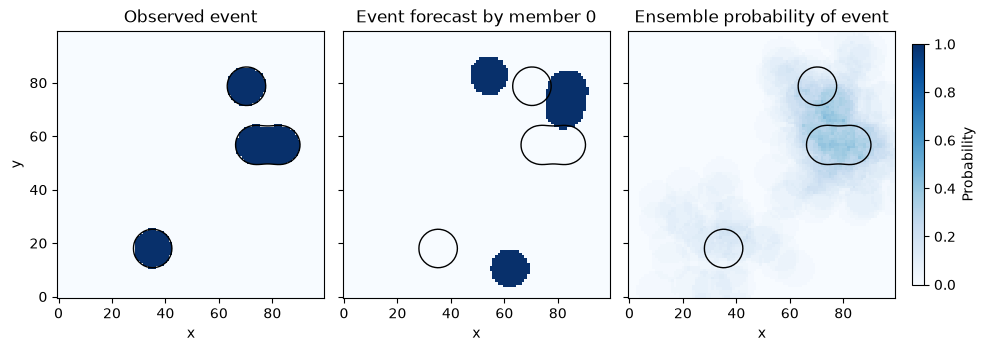

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
fig.set_layout_engine("compressed", wspace=0.04)

(obs > threshold).astype(int).plot.pcolormesh(ax=axes[0], cmap="Blues", add_colorbar=False)
(fcst.isel(member=0) > threshold).astype(int).plot.pcolormesh(ax=axes[1], cmap="Blues", add_colorbar=False)
prob = (fcst > threshold).mean("member").plot.pcolormesh(ax=axes[2], cmap="Blues", vmin=0, vmax=1, add_colorbar=False)
fig.colorbar(prob, ax=axes, label="Probability", shrink=0.9, pad=0.02)

titles = ["Observed event", "Event forecast by member 0", "Ensemble probability of event"]
for ax, title in zip(axes, titles):
    obs.plot.contour(ax=ax, levels=[threshold], colors="k", linewidths=1)
    ax.set_title(title)
    ax.set_aspect("equal")
for ax in axes[1:]:
    ax.set_ylabel("")  

## Calculating the pFSS

Now let's calculate the pFSS for a range of (square) window sizes. To see the benefit of the ensemble, we also calculate it using only the first 1 and 5 members. Using a single member is the same as calculating the FSS of a deterministic forecast.

We also show the "useful skill" level of $0.5 + f_o/2$, where $f_o$ is the fraction of the domain where the event was observed (Roberts & Lean, 2008). The smallest window size where a forecast exceeds this level is known as its skilful scale.

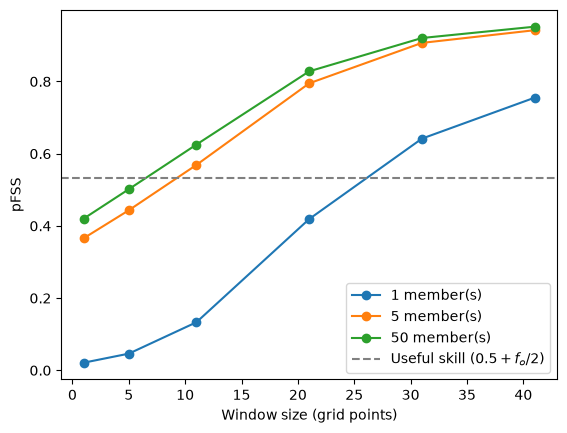

In [4]:
window_sizes = [1, 5, 11, 21, 31, 41]

for n_members in [1, 5, 50]:
    pfss = [
        pfss_for_ensemble(
            fcst.isel(member=slice(n_members)),
            obs,
            event_threshold=threshold,
            window_size=(w, w),
            spatial_dims=("y", "x"),
            ensemble_member_dim="member",
        ).item()
        for w in window_sizes
    ]
    plt.plot(window_sizes, pfss, marker="o", label=f"{n_members} member(s)")

f_o = (obs > threshold).mean().item()
plt.axhline(0.5 + f_o / 2, color="grey", linestyle="--", label="Useful skill ($0.5 + f_o/2$)")
plt.xlabel("Window size (grid points)")
plt.ylabel("pFSS")
plt.legend()
plt.show()

The pFSS increases with window size, since larger windows are more forgiving of displacement errors. The ensemble scores better than a single member at every window size, because the ensemble probability accounts for the uncertainty in where the storms will be. As a result, the ensemble has a smaller skilful scale. However, the benefit of adding more members diminishes: going from 5 to 50 members improves the pFSS much less than going from 1 to 5 members. Necker et al. (2024) found similar behaviour, with the pFSS saturating as ensemble size increases.

If `fcst` and `obs` have other dimensions (e.g. time), then by default they are aggregated over in the same way as `scores.spatial.fss_2d`. Use `preserve_dims` or `reduce_dims` to control this.

## A note of caution

A scoring rule is *proper* if a forecaster obtains the best expected score by forecasting what they truly believe ([Gneiting & Raftery, 2007](https://doi.org/10.1198/016214506000001437)). The pFSS is not a proper score. Since the forecast also appears in the denominator, a forecaster can sometimes improve their expected pFSS by issuing probabilities that differ from what they believe. This means that the pFSS can rank a worse forecast above a better one, and it may reward forecast systems that try to hedge the score.

## Things to try next

- Construct a synthetic example that shows the pFSS is not proper. Can you create a forecast that deliberately over- or under-states the probability of the event, yet receives a better pFSS than a forecast that issues the true probability?

## References

- Gneiting, T., & Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association*, 102(477), 359–378. [https://doi.org/10.1198/016214506000001437](https://doi.org/10.1198/016214506000001437)
- Necker, T., Wolfgruber, L., Kugler, L., Weissmann, M., Dorninger, M., & Serafin, S. (2024). The fractions skill score for ensemble forecast verification. *Quarterly Journal of the Royal Meteorological Society*, 150(764), 4457–4477. [https://doi.org/10.1002/qj.4824](https://doi.org/10.1002/qj.4824)
- Roberts, N. M., & Lean, H. W. (2008). Scale-selective verification of rainfall accumulations from high-resolution forecasts of convective events. *Monthly Weather Review*, 136(1), 78–97. [https://doi.org/10.1175/2007MWR2123.1](https://doi.org/10.1175/2007MWR2123.1)